# Classification

**Author:** *Ali H. El-Kassas* | Senior Data Scientist


In this notebook, we will go through an example project end to end.
 
Here are the main steps you will go through:
<ol>
<li>Look at the big picture.</li>
    <ul>
    <li>Frame the Problem</li>
    <li>Select a Performance Measure</li>
    </ul>  
        
<li>Get the data.</li>
    <ul>
    <li>Take a Quick Look at the Data</li>
    <li>Create a Test Set</li>
    </ul>  
<li>Discover and visualize the data (EDA)</li> 
<li>Experimenting with Attribute Combinations (Feature Engineering)</li>
<li>Prepare the data for ML algorithms.</li>
    <ul>
    <li>Data Cleaning</li>
    <li>Handling Text and Categorical Attributes</li>
    <li>Scaling</li>
    <li>Transformation Pipelines</li>
    </ul>  
<li>Select a model and train it</li>
<li>Fine-tune your model.</li>
<li>Error Analysis</li>
<li>Present your solution.</li>
<li>Launch, monitor, and maintain your system.</li>
</ol>

In [3]:
import seaborn as sns

sns.load_dataset?

Signature: sns.load_dataset(name, cache=True, data_home=None, **kws)
Docstring:
Load an example dataset from the online repository (requires internet).

This function provides quick access to a small number of example datasets
that are useful for documenting seaborn or generating reproducible examples
for bug reports. It is not necessary for normal usage.

Note that some of the datasets have a small amount of preprocessing applied
to define a proper ordering for categorical variables.

Use :func:`get_dataset_names` to see a list of available datasets.

Parameters
----------
name : str
    Name of the dataset (``{name}.csv`` on
    https://github.com/mwaskom/seaborn-data).
cache : boolean, optional
    If True, try to load from the local cache first, and save to the cache
    if a download is required.
data_home : string, optional
    The directory in which to cache data; see :func:`get_data_home`.
kws : keys and values, optional
    Additional keyword arguments are passed to passed thr

In [4]:
sns.load_dataset('tips')

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [5]:
# Load the dataset
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()

In [7]:
print(cancer)

{'data': array([[1.799e+01, 1.038e+01, 1.228e+02, ..., 2.654e-01, 4.601e-01,
        1.189e-01],
       [2.057e+01, 1.777e+01, 1.329e+02, ..., 1.860e-01, 2.750e-01,
        8.902e-02],
       [1.969e+01, 2.125e+01, 1.300e+02, ..., 2.430e-01, 3.613e-01,
        8.758e-02],
       ...,
       [1.660e+01, 2.808e+01, 1.083e+02, ..., 1.418e-01, 2.218e-01,
        7.820e-02],
       [2.060e+01, 2.933e+01, 1.401e+02, ..., 2.650e-01, 4.087e-01,
        1.240e-01],
       [7.760e+00, 2.454e+01, 4.792e+01, ..., 0.000e+00, 2.871e-01,
        7.039e-02]]), 'target': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
       1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0,
 

In [8]:
X, y = cancer.data, cancer.target

In [9]:
import pandas as pd

X = pd.DataFrame(X, columns=cancer.feature_names)
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [10]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [11]:
X.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


## Split the data

In [19]:
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
       1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0,
       0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0,

In [21]:
import pandas as pd

pd.Series(y).value_counts(normalize=True)

1    0.627417
0    0.372583
Name: proportion, dtype: float64

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
546,10.32,16.35,65.31,324.9,0.09434,0.04994,0.01012,0.005495,0.1885,0.06201,...,11.25,21.77,71.12,384.9,0.1285,0.08842,0.04384,0.02381,0.2681,0.07399
432,20.18,19.54,133.80,1250.0,0.11330,0.14890,0.21330,0.125900,0.1724,0.06053,...,22.03,25.07,146.00,1479.0,0.1665,0.29420,0.53080,0.21730,0.3032,0.08075
174,10.66,15.15,67.49,349.6,0.08792,0.04302,0.00000,0.000000,0.1928,0.05975,...,11.54,19.20,73.20,408.3,0.1076,0.06791,0.00000,0.00000,0.2710,0.06164
221,13.56,13.90,88.59,561.3,0.10510,0.11920,0.07860,0.044510,0.1962,0.06303,...,14.98,17.13,101.10,686.6,0.1376,0.26980,0.25770,0.09090,0.3065,0.08177
289,11.37,18.89,72.17,396.0,0.08713,0.05008,0.02399,0.021730,0.2013,0.05955,...,12.36,26.14,79.29,459.3,0.1118,0.09708,0.07529,0.06203,0.3267,0.06994
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
184,15.28,22.41,98.92,710.6,0.09057,0.10520,0.05375,0.032630,0.1727,0.06317,...,17.80,28.03,113.80,973.1,0.1301,0.32990,0.36300,0.12260,0.3175,0.09772
300,19.53,18.90,129.50,1217.0,0.11500,0.16420,0.21970,0.106200,0.1792,0.06552,...,25.93,26.24,171.10,2053.0,0.1495,0.41160,0.61210,0.19800,0.2968,0.09929
509,15.46,23.95,103.80,731.3,0.11830,0.18700,0.20300,0.085200,0.1807,0.07083,...,17.11,36.33,117.70,909.4,0.1732,0.49670,0.59110,0.21630,0.3013,0.10670
230,17.05,19.08,113.40,895.0,0.11410,0.15720,0.19100,0.109000,0.2131,0.06325,...,19.59,24.89,133.50,1189.0,0.1703,0.39340,0.50180,0.25430,0.3109,0.09061


## EDA

In [23]:
X_train.corr()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
mean radius,1.000000,0.314532,0.997789,0.988886,0.186062,0.515946,0.668475,0.822570,0.163217,-0.300273,...,0.970133,0.282822,0.965936,0.943351,0.119631,0.411654,0.524067,0.735769,0.175900,0.003668
mean texture,0.314532,1.000000,0.317985,0.309964,-0.041173,0.214740,0.276222,0.266221,0.055795,-0.083201,...,0.339574,0.912994,0.340889,0.331846,0.050191,0.254213,0.283289,0.268854,0.093769,0.107275
mean perimeter,0.997789,0.317985,1.000000,0.987834,0.224332,0.567508,0.709029,0.851740,0.200440,-0.248503,...,0.969674,0.287632,0.970918,0.943063,0.151513,0.454270,0.562180,0.763547,0.202702,0.048211
mean area,0.988886,0.309964,0.987834,1.000000,0.198963,0.512307,0.678012,0.824948,0.166673,-0.267226,...,0.962829,0.271958,0.959360,0.957080,0.131227,0.392119,0.511134,0.716582,0.157698,0.005322
mean smoothness,0.186062,-0.041173,0.224332,0.198963,1.000000,0.661769,0.550461,0.572164,0.570054,0.566008,...,0.231080,0.028475,0.258177,0.228156,0.798808,0.495236,0.473253,0.518242,0.430442,0.503625
mean compactness,0.515946,0.214740,0.567508,0.512307,0.661769,1.000000,0.895918,0.842957,0.623672,0.569720,...,0.544975,0.234586,0.599982,0.522258,0.557208,0.866864,0.832984,0.821914,0.533571,0.683961
mean concavity,0.668475,0.276222,0.709029,0.678012,0.550461,0.895918,1.000000,0.922474,0.527835,0.367603,...,0.677343,0.276533,0.719681,0.664738,0.458859,0.755946,0.887825,0.858758,0.429450,0.522603
mean concave points,0.822570,0.266221,0.851740,0.824948,0.572164,0.842957,0.922474,1.000000,0.486367,0.185705,...,0.830130,0.270308,0.857224,0.810853,0.456692,0.677586,0.766984,0.910330,0.403524,0.377917
mean symmetry,0.163217,0.055795,0.200440,0.166673,0.570054,0.623672,0.527835,0.486367,1.000000,0.492612,...,0.200339,0.081881,0.236714,0.189996,0.427530,0.497527,0.466068,0.454245,0.721222,0.455720
mean fractal dimension,-0.300273,-0.083201,-0.248503,-0.267226,0.566008,0.569720,0.367603,0.185705,0.492612,1.000000,...,-0.241707,-0.053001,-0.191768,-0.216649,0.487220,0.473688,0.373834,0.190987,0.347184,0.771330


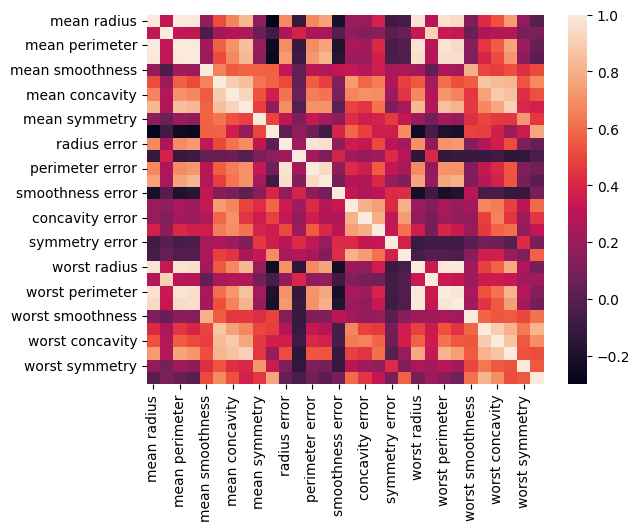

In [25]:
import seaborn as sns

sns.heatmap(X_train.corr());

In [29]:
X_y_train = X_train.copy()
X_y_train['label'] = y_train

corr_matrix = X_y_train.corr()
corr_matrix

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,label
mean radius,1.000000,0.314532,0.997789,0.988886,0.186062,0.515946,0.668475,0.822570,0.163217,-0.300273,...,0.282822,0.965936,0.943351,0.119631,0.411654,0.524067,0.735769,0.175900,0.003668,-0.732224
mean texture,0.314532,1.000000,0.317985,0.309964,-0.041173,0.214740,0.276222,0.266221,0.055795,-0.083201,...,0.912994,0.340889,0.331846,0.050191,0.254213,0.283289,0.268854,0.093769,0.107275,-0.409384
mean perimeter,0.997789,0.317985,1.000000,0.987834,0.224332,0.567508,0.709029,0.851740,0.200440,-0.248503,...,0.287632,0.970918,0.943063,0.151513,0.454270,0.562180,0.763547,0.202702,0.048211,-0.745132
mean area,0.988886,0.309964,0.987834,1.000000,0.198963,0.512307,0.678012,0.824948,0.166673,-0.267226,...,0.271958,0.959360,0.957080,0.131227,0.392119,0.511134,0.716582,0.157698,0.005322,-0.713409
mean smoothness,0.186062,-0.041173,0.224332,0.198963,1.000000,0.661769,0.550461,0.572164,0.570054,0.566008,...,0.028475,0.258177,0.228156,0.798808,0.495236,0.473253,0.518242,0.430442,0.503625,-0.392200
mean compactness,0.515946,0.214740,0.567508,0.512307,0.661769,1.000000,0.895918,0.842957,0.623672,0.569720,...,0.234586,0.599982,0.522258,0.557208,0.866864,0.832984,0.821914,0.533571,0.683961,-0.610722
mean concavity,0.668475,0.276222,0.709029,0.678012,0.550461,0.895918,1.000000,0.922474,0.527835,0.367603,...,0.276533,0.719681,0.664738,0.458859,0.755946,0.887825,0.858758,0.429450,0.522603,-0.692052
mean concave points,0.822570,0.266221,0.851740,0.824948,0.572164,0.842957,0.922474,1.000000,0.486367,0.185705,...,0.270308,0.857224,0.810853,0.456692,0.677586,0.766984,0.910330,0.403524,0.377917,-0.779907
mean symmetry,0.163217,0.055795,0.200440,0.166673,0.570054,0.623672,0.527835,0.486367,1.000000,0.492612,...,0.081881,0.236714,0.189996,0.427530,0.497527,0.466068,0.454245,0.721222,0.455720,-0.358370
mean fractal dimension,-0.300273,-0.083201,-0.248503,-0.267226,0.566008,0.569720,0.367603,0.185705,0.492612,1.000000,...,-0.053001,-0.191768,-0.216649,0.487220,0.473688,0.373834,0.190987,0.347184,0.771330,-0.001027


In [33]:
corr_matrix['label'].abs().sort_values(ascending=False)

label                      1.000000
worst concave points       0.798176
worst perimeter            0.783376
mean concave points        0.779907
worst radius               0.776390
mean perimeter             0.745132
worst area                 0.737965
mean radius                0.732224
mean area                  0.713409
mean concavity             0.692052
worst concavity            0.668368
mean compactness           0.610722
worst compactness          0.602331
area error                 0.567197
radius error               0.565074
perimeter error            0.551905
worst texture              0.450765
worst symmetry             0.430422
worst smoothness           0.429227
concave points error       0.418560
mean texture               0.409384
mean smoothness            0.392200
mean symmetry              0.358370
worst fractal dimension    0.327308
compactness error          0.291239
concavity error            0.252785
smoothness error           0.070507
fractal dimension error    0

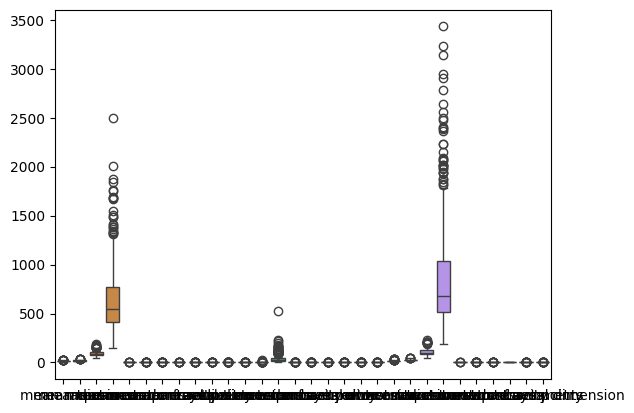

In [35]:
sns.boxplot(X_train);

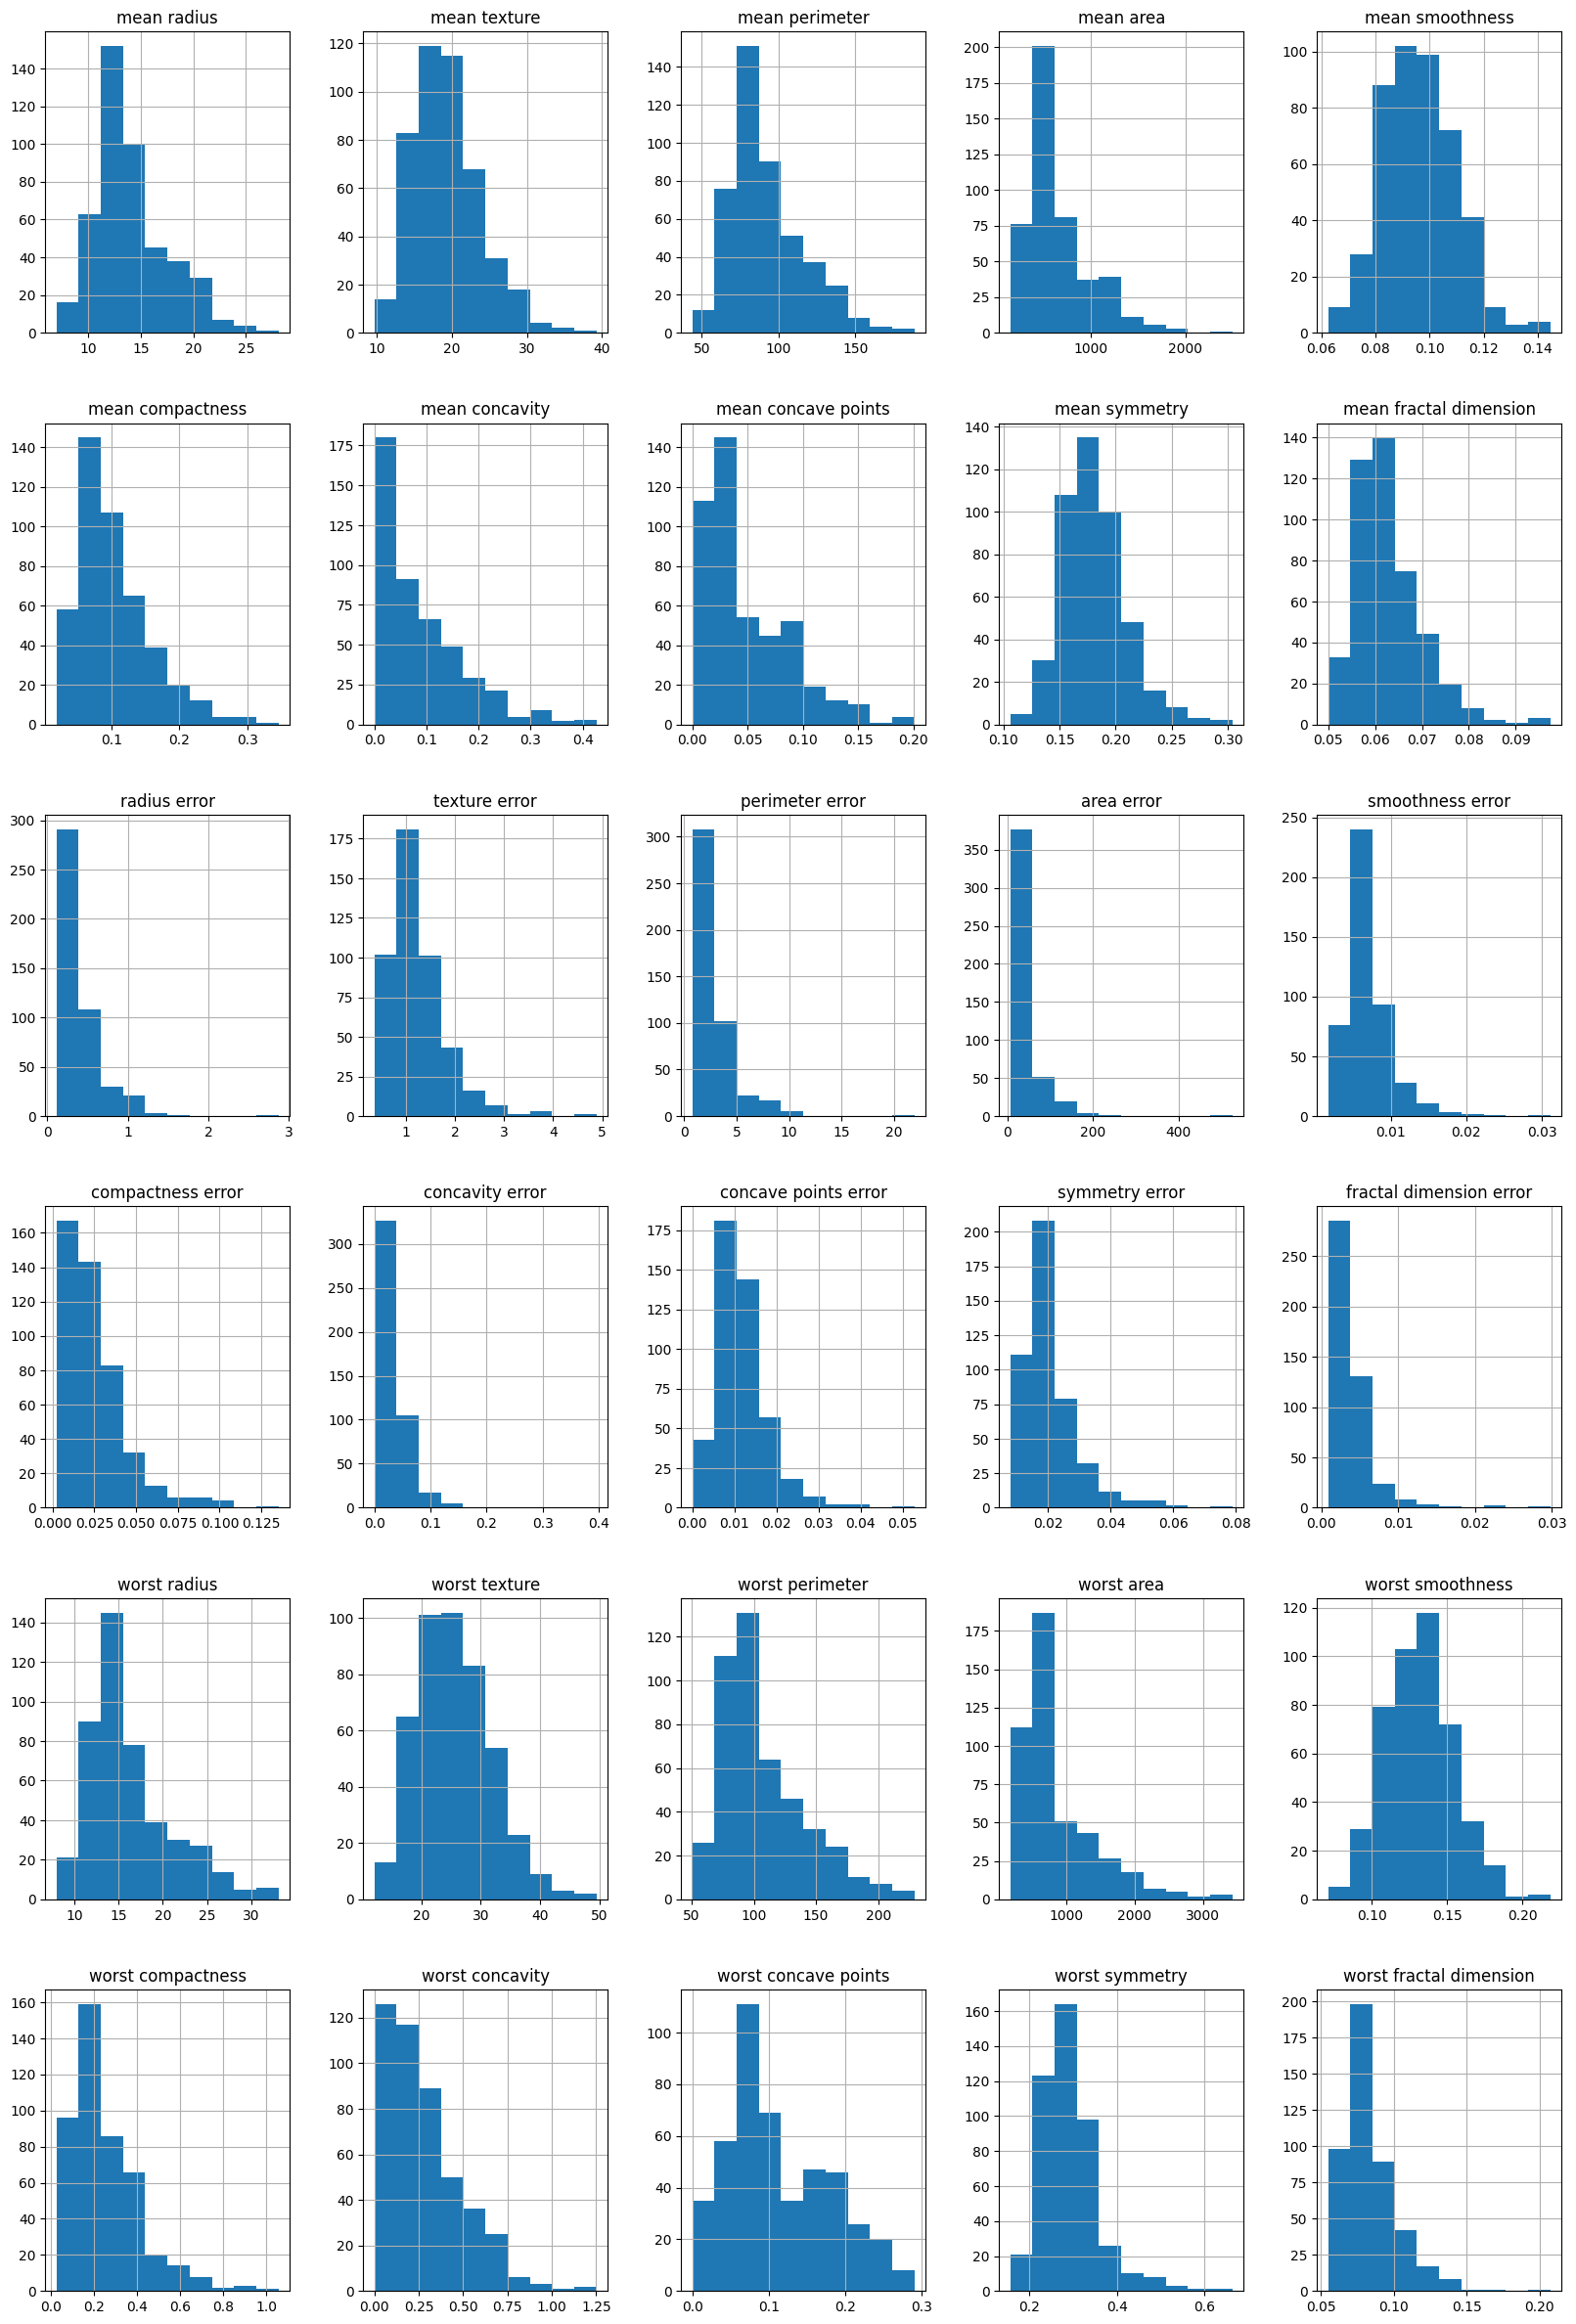

In [38]:
X_train.hist(figsize=(20, 30));

## Feature Engineering

## Preprocessing

## Modeling

In [ ]:
# Step1: import the model that you will use
from sklearn.neighbors import KNeighborsClassifier

# Step2: init the model
model = KNeighborsClassifier()

# Step 3: Train -> 
model.fit(X_train, y_train)

In [39]:
# Step1: import the model that you will use
from sklearn.tree import DecisionTreeClassifier

# Step2: init the model
model = DecisionTreeClassifier()

# Step 3: Train -> find the best questions or conditions
model.fit(X_train, y_train)

DecisionTreeClassifier()

In [46]:
model.get_depth()

7

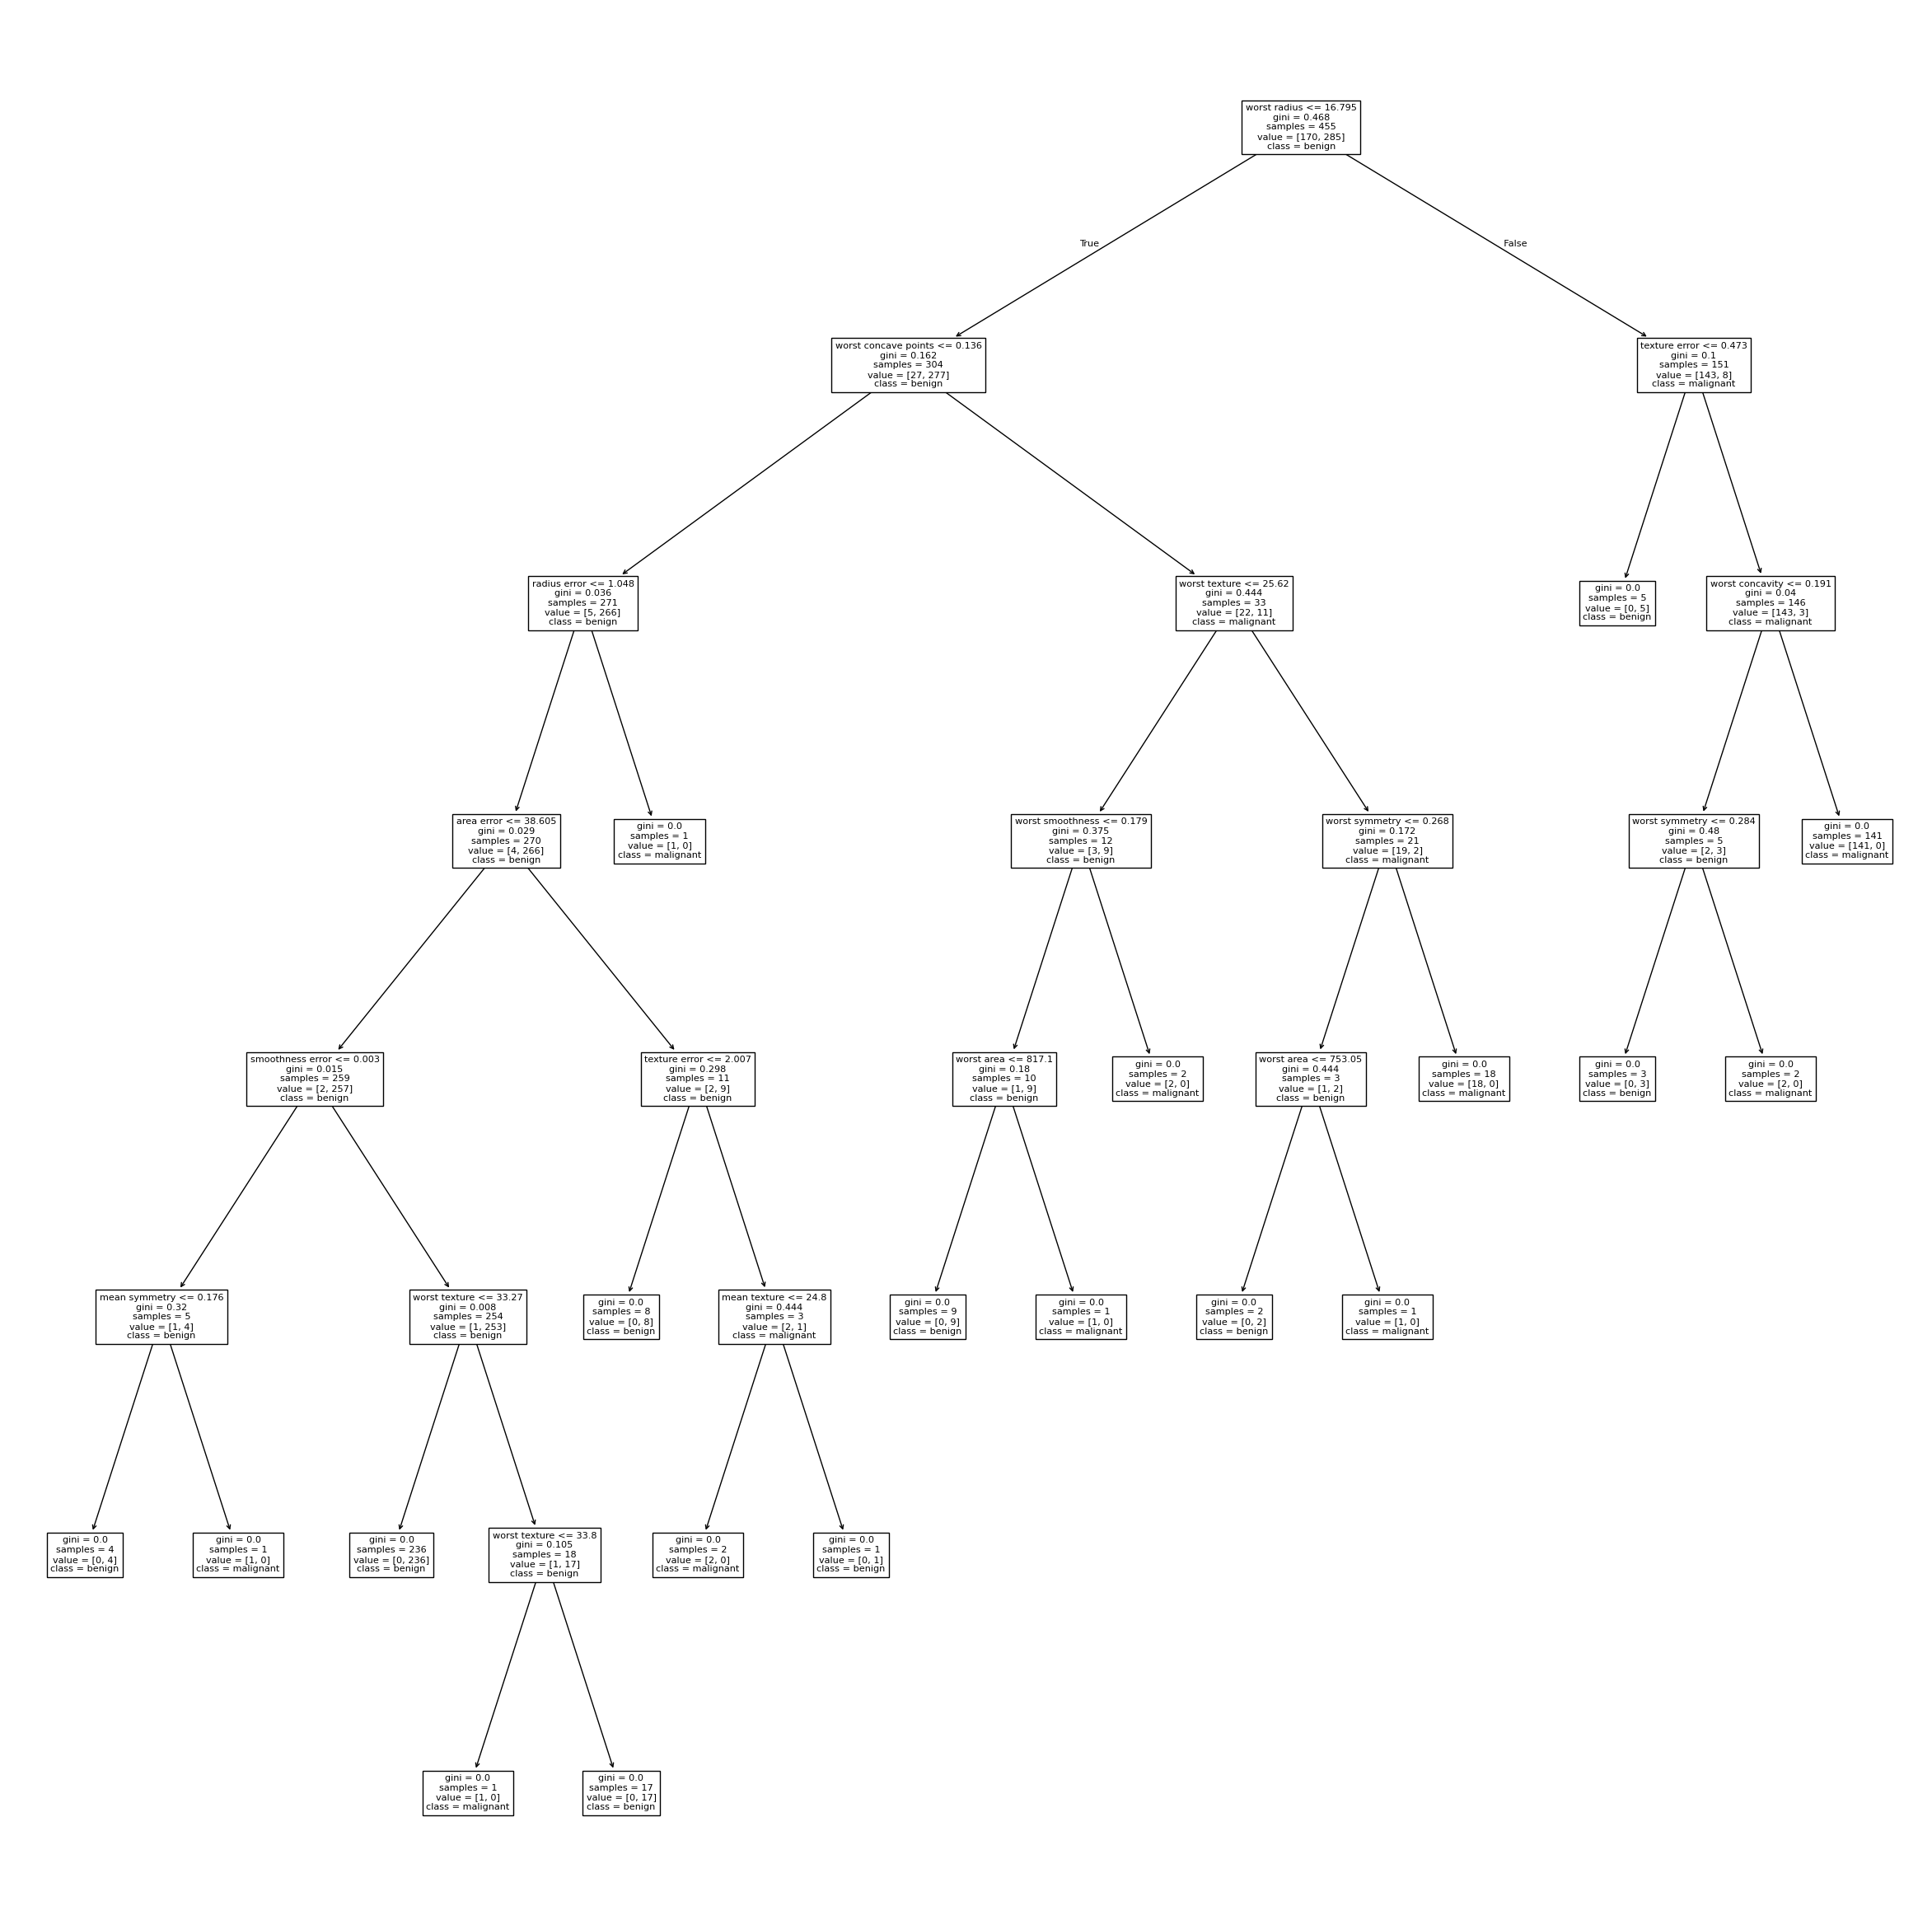

In [40]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(30, 30))
tree_dot = plot_tree(model,
                     feature_names=cancer.feature_names,
                     class_names=cancer.target_names)

In [41]:
from sklearn.metrics import recall_score

#recall_score(real, pred)
pred_train = model.predict(X_train)

recall_score(y_train, pred_train)

1.0

In [42]:
pred_test = model.predict(X_test)

recall_score(y_test, pred_test)

0.9027777777777778

## Reguralization -> Pruning

In [61]:
from sklearn.tree import DecisionTreeClassifier

smaller_tree = DecisionTreeClassifier(max_depth=2, random_state=42)

smaller_tree.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=2, random_state=42)

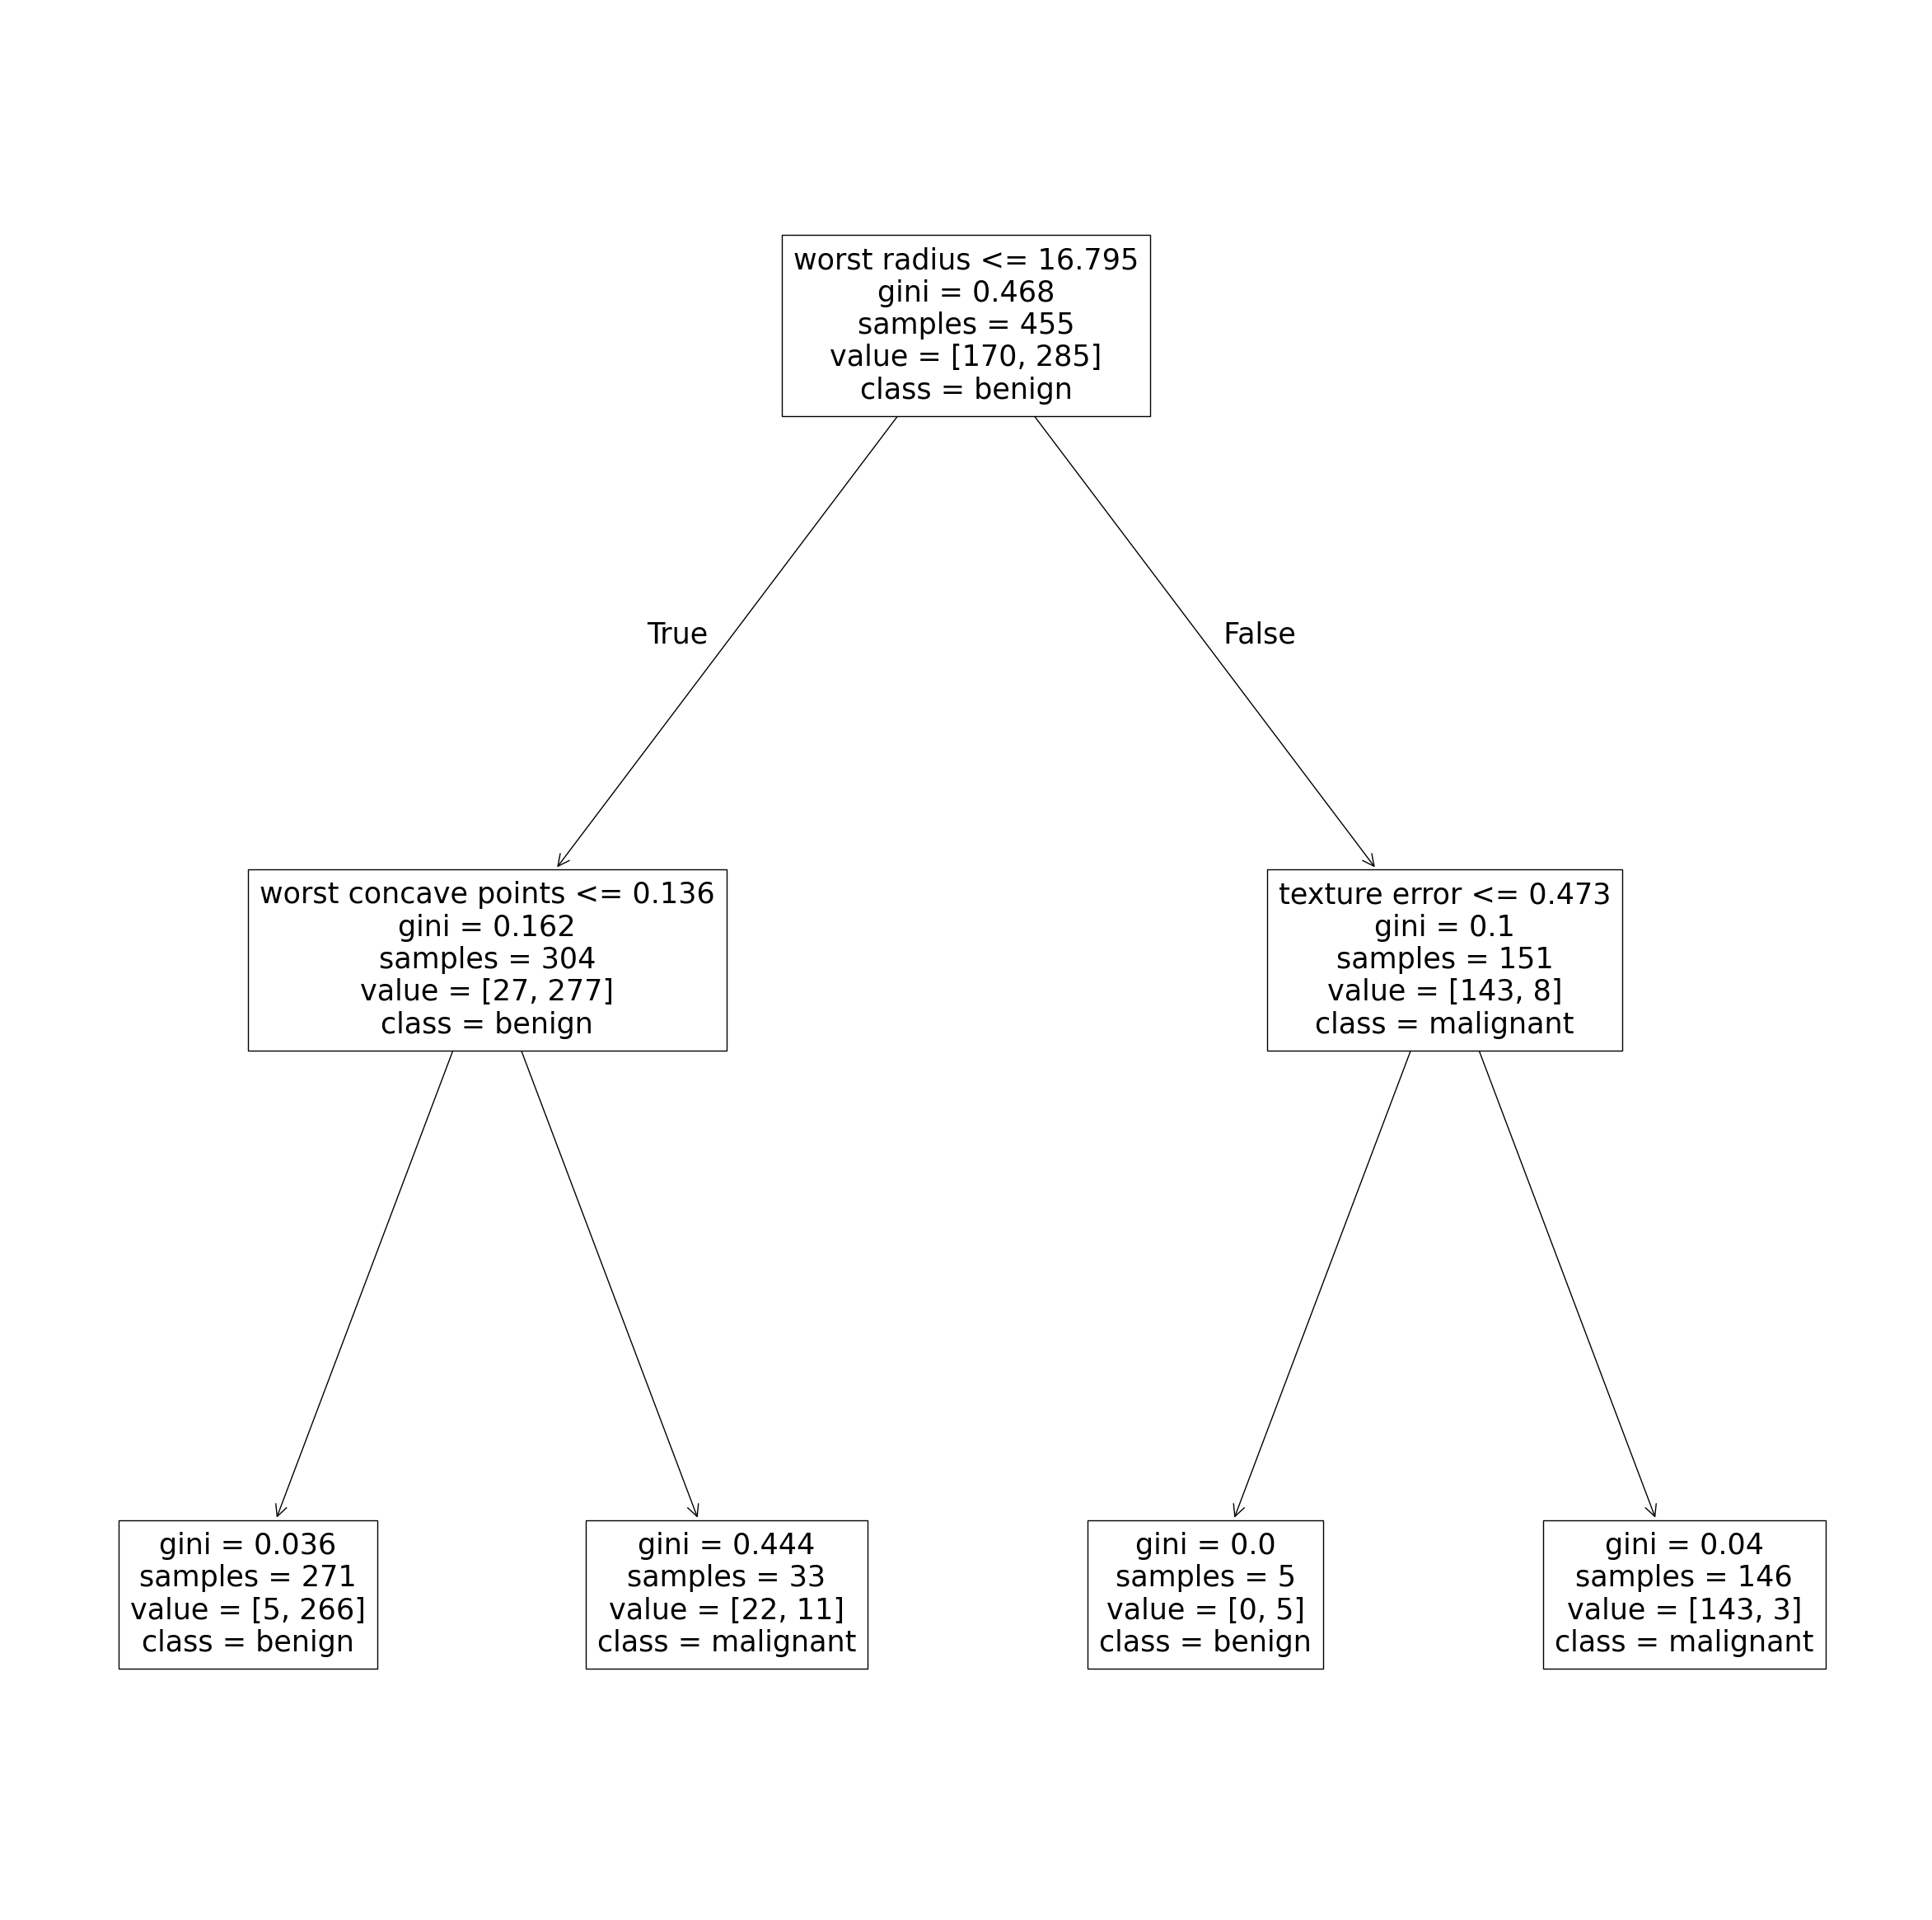

In [62]:
plt.figure(figsize=(30, 30))
tree_dot = plot_tree(smaller_tree,
                     feature_names=cancer.feature_names,
                     class_names=cancer.target_names)

In [63]:
pred_test = smaller_tree.predict(X_test)

recall_score(y_test, pred_test, pos_label=0)

0.9523809523809523

In [64]:
from sklearn.metrics import accuracy_score, precision_score, f1_score, classification_report

print(classification_report(y_test, pred_test))

              precision    recall  f1-score   support

           0       0.80      0.95      0.87        42
           1       0.97      0.86      0.91        72

    accuracy                           0.89       114
   macro avg       0.88      0.91      0.89       114
weighted avg       0.91      0.89      0.90       114



In [65]:
accuracy_score(y_test, pred_test)

0.8947368421052632

In [59]:
precision_score(y_test, pred_test,  pos_label=0)

0.926829268292683

In [60]:
f1_score(y_test, pred_test, pos_label=0)

0.9156626506024096